# 07c · Fase 1: DeepFM (filtro personal) — correr en Colab

Etapa 7, paso c. El DeepFM (Guo et al., 2017) aprende el gusto de cada usuario con su historial de **train** (35 outfits por usuario) y puntúa sus candidatos de valid y test (paso a). Es el **experimento 1** ("DeepFM solo") y el filtro de la primera etapa para el ranking final (paso d).

- **Qué ve:** los datos que daría el usuario al registrarse (edad, género, ciudad, clima, estilo favorito y su ID) y el outfit con el mismo vector de 464 columnas de la fase 2. **No ve** su arquetipo ni los pesos de su gusto simulado: eso es lo que tiene que aprender.
- **Tuning:** dimensión de embedding, dropout y regularización, elegidos por la pérdida en el historial de **valid**. Después, 3 semillas.
- **Línea base:** regresión logística con las mismas variables.

**Cómo correrlo:** igual que el 7b. Colab → GPU (T4) → *Ejecutar todas* (unos 10 min). Al final se descarga `etapa7c_resultados.zip`: pégalo **sin descomprimir** en la carpeta `modelo-fly`, al lado de `README.md`.

In [1]:
import os
import subprocess
import sys
from pathlib import Path

RAMA = "hito3/etapa7-modelos"
URL = "https://github.com/sowiexsker894/Predicci-n-de-compatibilidad-de-outfits-desde-el-conectoma-del-Giant-Fiber-System.git"

EN_COLAB = "google.colab" in sys.modules
if EN_COLAB:
    if not Path("/content/modelo-fly").exists():
        subprocess.run(["git", "clone", "-q", "--depth", "1", "-b", RAMA, URL, "/content/modelo-fly"], check=True)
    ROOT = Path("/content/modelo-fly")
else:
    ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "data" / "raw").is_dir())
sys.path.insert(0, str(ROOT / "src"))
import torch
DISPOSITIVO = "cuda" if torch.cuda.is_available() else "cpu"
print("Repositorio:", ROOT, "| torch", torch.__version__, "| dispositivo:", DISPOSITIVO)

Repositorio: /content/modelo-fly | torch 2.14.1+cu130 | dispositivo: cuda


## 1. Datos

In [2]:
import json
import time

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display
from scipy import sparse
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import log_loss, roc_auc_score

from modelo_fly.caracteristicas import CAMPOS_USUARIO, GRUPOS_SLOT, codificar, codificar_usuarios
from modelo_fly.ranking import resumen
from modelo_fly.usuarios import cargar_items

PROC = ROOT / "data" / "processed" / "hito3"
SALIDA = ROOT / "salida_7c"
SALIDA.mkdir(exist_ok=True)
SEMILLAS = [0, 1, 2]
t0 = time.time()

items, atrib, _ = cargar_items(PROC)
usuarios = pd.read_csv(PROC / "usuarios.csv")
historial = pd.read_csv(PROC / "historial.csv")
cand = pd.read_csv(PROC / "candidatos.csv")
fila_u, N_VOCAB = codificar_usuarios(usuarios)

def preparar(df):
    U = np.array([fila_u[u] for u in df["user_id"]])
    X = codificar(df["item_ids"].str.split("|").tolist(), atrib)
    return U, X

parte = {p: historial[historial["particion"] == p].reset_index(drop=True) for p in ["train", "valid", "test"]}
datos = {p: preparar(d) for p, d in parte.items()}
y = {p: d["aceptado"].to_numpy() for p, d in parte.items()}
U_c, X_c = preparar(cand)
print("Historial:", {p: len(d) for p, d in parte.items()}, "| candidatos:", len(cand), "| vocabulario de usuario:", N_VOCAB)

def disperso(U, X):
    """Usuario one-hot + outfit, para la regresión logística."""
    filas = np.repeat(np.arange(len(U)), U.shape[1])
    Uoh = sparse.csr_matrix((np.ones(U.size), (filas, U.ravel())), shape=(len(U), N_VOCAB))
    return sparse.hstack([Uoh, sparse.csr_matrix(X)]).tocsr()

Historial: {'train': 12250, 'valid': 2450, 'test': 2800} | candidatos: 52500 | vocabulario de usuario: 371


In [3]:
# Línea base: regresión logística con las mismas variables (sin interacciones). C se elige en valid.
Z = {p: disperso(*datos[p]) for p in datos}
Z_c = disperso(U_c, X_c)
prueba = {C: LogisticRegression(C=C, max_iter=3000).fit(Z["train"], y["train"]) for C in [0.01, 0.1, 1.0]}
C_mejor = min(prueba, key=lambda C: log_loss(y["valid"], prueba[C].predict_proba(Z["valid"])[:, 1]))
logreg = prueba[C_mejor]
cand["logreg"] = logreg.predict_proba(Z_c)[:, 1]
print("Logística: C =", C_mejor, "| AUC historial test:",
      round(roc_auc_score(y["test"], logreg.predict_proba(Z["test"])[:, 1]), 3))

Logística: C = 0.01 | AUC historial test: 0.646


## 2. DeepFM: tuning y entrenamiento

Se prueban 8 configuraciones con la semilla 0 y se elige la de menor pérdida en el historial de valid. Después se entrenan las 3 semillas con esa configuración.

In [4]:
from modelo_fly.deepfm import DeepFM, entrenar, predecir

grupos = list(GRUPOS_SLOT.values())
GRILLA = [{"k": k, "dropout": d, "peso": w} for k in [8, 16] for d in [0.1, 0.3] for w in [1e-5, 1e-3]]

def ajustar(cfg, semilla):
    m = DeepFM(N_VOCAB, X_c.shape[1], grupos, k=cfg["k"], dropout=cfg["dropout"])
    c = entrenar(m, *datos["train"], y["train"], *datos["valid"], y["valid"], semilla=semilla,
                 peso=cfg["peso"], dispositivo=DISPOSITIVO)
    return m, c

t = time.time()
pruebas = []
for cfg in GRILLA:
    m, c = ajustar(cfg, SEMILLAS[0])
    pruebas.append({**cfg, "epocas": len(c), "perdida_valid": round(min(c), 4), "_m": m})
tabla_tuning = pd.DataFrame(pruebas).drop(columns="_m").sort_values("perdida_valid")
display(tabla_tuning)
mejor = min(pruebas, key=lambda r: r["perdida_valid"])
CFG = {k: mejor[k] for k in ["k", "dropout", "peso"]}
print("Configuración elegida:", CFG, f"| {time.time() - t:.0f} s")

modelos = {SEMILLAS[0]: mejor["_m"]}
for s in SEMILLAS[1:]:
    modelos[s], _ = ajustar(CFG, s)
for s, m in modelos.items():
    cand[f"deepfm_s{s}"] = predecir(m, U_c, X_c, DISPOSITIVO)
    print(f"semilla {s}: AUC historial test {roc_auc_score(y['test'], predecir(m, *datos['test'], DISPOSITIVO)):.3f}")

,k,dropout,peso,epocas,perdida_valid
0,8,0.1,0.00001,16,0.6603
7,16,0.3,0.00100,15,0.6615
5,16,0.1,0.00100,12,0.6617
6,16,0.3,0.00001,14,0.6617
4,16,0.1,0.00001,12,0.6618
1,8,0.1,0.00100,9,0.6628
3,8,0.3,0.00100,12,0.6635
2,8,0.3,0.00001,9,0.6636


Configuración elegida: {'k': 8, 'dropout': 0.1, 'peso': 1e-05} | 35 s
semilla 0: AUC historial test 0.656
semilla 1: AUC historial test 0.655
semilla 2: AUC historial test 0.651


## 3. Experimento 1: ranking con el DeepFM solo

NDCG@K, Recall@K (normalizado por min(K, aceptados)) y HitRate@K por usuario sobre los 100 candidatos de test (`src/modelo_fly/ranking.py`). Referencias: al azar y el techo (probabilidad real de la simulación).

In [5]:
rng = np.random.default_rng(0)
cand["azar"] = rng.random(len(cand))
cand = cand.merge(usuarios[["user_id", "grupo"]], on="user_id", how="left")
filas = []
for particion in ["valid", "test"]:
    d = cand[cand["particion"] == particion]
    for nombre, cols in [("azar", ["azar"]), ("techo (p_real)", ["p_real"]), ("logistica", ["logreg"]),
                         ("deepfm", [f"deepfm_s{s}" for s in SEMILLAS])]:
        for col in cols:
            for grupo, g in [("todos", d), *d.groupby("grupo")]:
                filas.append({"particion": particion, "modelo": nombre, "columna": col, "grupo": grupo, **resumen(g, col)})
ranking = pd.DataFrame(filas)
metricas = ["NDCG@5", "NDCG@10", "Recall@5", "Recall@10", "HitRate@5"]
display(ranking[ranking["particion"] == "test"].groupby(["grupo", "modelo"], sort=False)[metricas]
        .agg(["mean", "std"]).round(3))

NDCG@5        NDCG@10        Recall@5         \
                               mean    std    mean    std     mean    std   
grupo         modelo                                                        
todos         azar            0.492    NaN   0.489    NaN    0.493    NaN   
mixto         azar            0.487    NaN   0.487    NaN    0.489    NaN   
transferencia azar            0.521    NaN   0.503    NaN    0.516    NaN   
todos         techo (p_real)  0.919    NaN   0.905    NaN    0.920    NaN   
mixto         techo (p_real)  0.916    NaN   0.903    NaN    0.917    NaN   
transferencia techo (p_real)  0.932    NaN   0.915    NaN    0.936    NaN   
todos         logistica       0.697    NaN   0.687    NaN    0.696    NaN   
mixto         logistica       0.695    NaN   0.684    NaN    0.693    NaN   
transferencia logistica       0.710    NaN   0.706    NaN    0.712    NaN   
todos         deepfm          0.750  0.014   0.734  0.013    0.741  0.013   
mixto         deepfm          0.750  0.014   0.731  0.013    0.738  0.013   
transferencia deepfm          0.753  0.020   0.750  0.011    0.756  0.017   

                             Recall@10        HitRate@5         
                                  mean    std      mean    std  
grupo         modelo                                            
todos         azar               0.488    NaN     0.966    NaN  
mixto         azar               0.487    NaN     0.967    NaN  
transferencia azar               0.494    NaN     0.960    NaN  
todos         techo (p_real)     0.900    NaN     1.000    NaN  
mixto         techo (p_real)     0.898    NaN     1.000    NaN  
transferencia techo (p_real)     0.910    NaN     1.000    NaN  
todos         logistica          0.681    NaN     0.997    NaN  
mixto         logistica          0.677    NaN     0.997    NaN  
transferencia logistica          0.704    NaN     1.000    NaN  
todos         deepfm             0.721  0.012     0.995  0.002  
mixto         deepfm             0.716  0.013     0.996  0.002  
transferencia deepfm             0.749  0.002     0.993  0.012

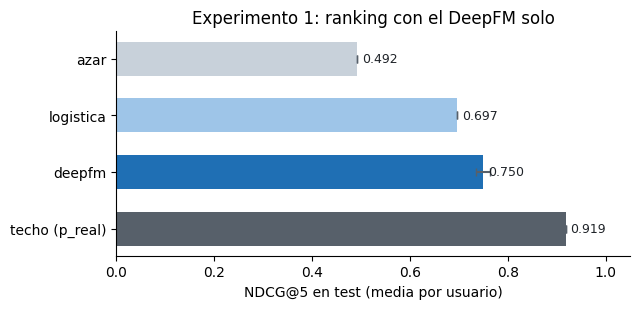

In [6]:
te = ranking[(ranking["particion"] == "test") & (ranking["grupo"] == "todos")]
g = te.groupby("modelo", sort=False)["NDCG@5"].agg(["mean", "std"]).reindex(["azar", "logistica", "deepfm", "techo (p_real)"])
fig, ax = plt.subplots(figsize=(6.5, 3.2))
pos = np.arange(len(g))[::-1]
ax.barh(pos, g["mean"], xerr=g["std"].fillna(0), color=["#c8d1da", "#9ec5e8", "#1f6fb4", "#57606a"], height=0.6,
        error_kw={"ecolor": "#57606a", "capsize": 3})
ax.set_yticks(pos, g.index)
for y_, v in zip(pos, g["mean"]):
    ax.text(v + 0.01, y_, f"{v:.3f}", va="center", fontsize=9, color="#1f2328")
ax.set_xlim(0, 1.05)
ax.set_xlabel("NDCG@5 en test (media por usuario)")
ax.set_title("Experimento 1: ranking con el DeepFM solo")
for s in ["top", "right"]:
    ax.spines[s].set_visible(False)
fig.tight_layout()
fig.savefig(SALIDA / "fig_deepfm_ndcg.png", dpi=150)
plt.show()

## 4. Guardar y descargar

In [7]:
cols = ["user_id", "outfit_id", "particion", "logreg", *[f"deepfm_s{s}" for s in SEMILLAS]]
cand[cols].round(5).to_csv(SALIDA / "deepfm_pred_candidatos.csv.gz", index=False)
ranking.round(5).to_csv(SALIDA / "deepfm_ranking.csv", index=False)
tabla_tuning.to_csv(SALIDA / "deepfm_tuning.csv", index=False)
(SALIDA / "deepfm_meta.json").write_text(json.dumps({
    "rama": RAMA, "dispositivo": DISPOSITIVO, "torch": torch.__version__, "configuracion": CFG,
    "C_logistica": C_mejor, "semillas": SEMILLAS, "minutos": round((time.time() - t0) / 60, 1)}, indent=2),
    encoding="utf-8")
import shutil
zip_path = shutil.make_archive(str(ROOT / "etapa7c_resultados"), "zip", SALIDA)
print("Listo en", round((time.time() - t0) / 60, 1), "min:", zip_path)
if EN_COLAB:
    from google.colab import files
    files.download(zip_path)

Listo en 1.5 min: /content/modelo-fly/etapa7c_resultados.zip


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>